# **Vision** **transformer**

In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import vit_b_16, ViT_B_16_Weights
from google.colab import drive


TRAIN_DATA_PATH = './data/real_vs_fake/train'
VALID_DATA_PATH = './data/real_vs_fake/valid'
BATCH_SIZE = 32
IMAGE_SIZE = 224
LEARNING_RATE = 5e-5
EPOCHS = 20
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print(f"Training on device: {DEVICE}")

# Normalize images using ImageNet pre-trained statistics
imagenet_normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

# Training data augmentations
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    imagenet_normalize
])

# Validation data transformations
val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    imagenet_normalize
])

# Load datasets
train_dataset = datasets.ImageFolder(root=TRAIN_DATA_PATH, transform=train_transform)
val_dataset = datasets.ImageFolder(root=VALID_DATA_PATH, transform=val_transform)

# Data loaders setup
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train classes found: {train_dataset.classes}")
print(f"Training set size: {len(train_dataset)} | Validation set size: {len(val_dataset)}")



# --- Load Pre-trained ViT Model ---

weights = ViT_B_16_Weights.DEFAULT
model = vit_b_16(weights=weights)

in_features = model.heads.head.in_features
model.heads.head = nn.Linear(in_features, 2)

model = model.to(DEVICE)



# --- Loss Function, Optimizer, and Scheduler ---
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.7)

best_val_loss = float('inf')
SAVE_PATH = '/content/drive/MyDrive/best_vit_fake_detection.pth'

# --- Training Loop ---
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print("-" * 10)


    for inputs, labels in train_loader:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    # Update learning rate
    scheduler.step()
    current_lr = scheduler.get_last_lr()[0]

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100 * correct / total
    print(f"Train Loss: {epoch_loss:.4f}, Train Acc: {epoch_acc:.2f}%, LR: {current_lr:.6f}")

    # --- Validation Phase ---
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            outputs = model(inputs)

            loss = criterion(outputs, labels)
            val_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_acc = 100 * val_correct / val_total
    avg_val_loss = val_loss / len(val_loader)
    print(f"Validation Loss: {avg_val_loss:.4f}, Validation Acc: {val_acc:.2f}%")

    # --- Save Best Model ---
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), SAVE_PATH)


        print(f"--> [SAVE] New best validation loss reached! Model saved to: {SAVE_PATH}")

print("\nTraining Process Finished!")

# --- Final Evaluation on Test Set ---

print("\n" + "="*30)
print("Loading BEST model for final evaluation on Test set...")
print("="*30)

model.load_state_dict(torch.load(SAVE_PATH))

model.eval()

test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        outputs = model(inputs)

        loss = criterion(outputs, labels)
        test_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_acc = 100 * test_correct / test_total
avg_test_loss = test_loss / len(test_loader)

print(f"FINAL TEST RESULTS | Loss: {avg_test_loss:.4f} | Accuracy: {test_acc:.2f}%")

Training on device: cuda
Train classes found: ['fake', 'real']
Training set size: 100000 | Validation set size: 20000
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:03<00:00, 105MB/s]



Epoch 1/20
----------
Train Loss: 0.1197, Train Acc: 95.20%, LR: 0.000050
Validation Loss: 0.1159, Validation Acc: 95.64%
--> [SAVE] New best validation loss reached! Model saved to: /content/drive/MyDrive/best_vit_fake_detection.pth

Epoch 2/20
----------
Train Loss: 0.0555, Train Acc: 97.97%, LR: 0.000050
Validation Loss: 0.0265, Validation Acc: 98.98%
--> [SAVE] New best validation loss reached! Model saved to: /content/drive/MyDrive/best_vit_fake_detection.pth

Epoch 3/20
----------
Train Loss: 0.0433, Train Acc: 98.38%, LR: 0.000035
Validation Loss: 0.0272, Validation Acc: 99.03%

Epoch 4/20
----------
Train Loss: 0.0231, Train Acc: 99.17%, LR: 0.000035
Validation Loss: 0.0227, Validation Acc: 99.22%
--> [SAVE] New best validation loss reached! Model saved to: /content/drive/MyDrive/best_vit_fake_detection.pth

Epoch 5/20
----------
Train Loss: 0.0205, Train Acc: 99.25%, LR: 0.000035


# Confusion Matrix

Loading model architecture...
Loading trained weights from: /content/drive/MyDrive/best_vit_fake_detection.pth
Running inference on Test Set... Please wait.
Saved Confusion Matrix image to 'confusion_matrix_vit.png'


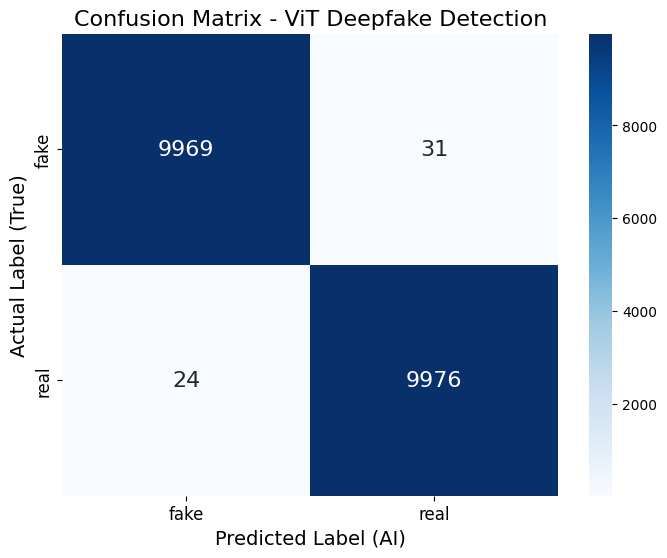


--- Classification Report ---
              precision    recall  f1-score   support

        fake       1.00      1.00      1.00     10000
        real       1.00      1.00      1.00     10000

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000



In [ ]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from torchvision.models import vit_b_16, ViT_B_16_Weights
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


# 1. Settings and Paths
TEST_DATA_PATH = '/content/dataset/real_vs_fake/real-vs-fake/test' 
MODEL_WEIGHTS_PATH = '/content/drive/MyDrive/best_vit_fake_detection.pth'
IMAGE_SIZE = 224
BATCH_SIZE = 32
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'


# 2. Data Preparation

imagenet_normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    imagenet_normalize
])

test_dataset = datasets.ImageFolder(root=TEST_DATA_PATH, transform=test_transform)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
class_names = test_dataset.classes


# 3. Load Trained Model

print("Loading model architecture...")
model = vit_b_16(weights=None)
in_features = model.heads.head.in_features
model.heads.head = nn.Linear(in_features, 2) 

print(f"Loading trained weights from: {MODEL_WEIGHTS_PATH}")
model.load_state_dict(torch.load(MODEL_WEIGHTS_PATH, map_location=DEVICE))
model = model.to(DEVICE)
model.eval() 


# 4. Run Inference on Test Set

all_preds = []
all_labels = []

print("Running inference on Test Set... Please wait.")
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)

        # Store predictions and labels
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())


# 5. Generate Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            annot_kws={"size": 16})

plt.title('Confusion Matrix - ViT Deepfake Detection', fontsize=16)
plt.ylabel('Actual Label (True)', fontsize=14)
plt.xlabel('Predicted Label (AI)', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)


plt.savefig('confusion_matrix_vit.png', dpi=300, bbox_inches='tight')
print("Saved Confusion Matrix image to 'confusion_matrix_vit.png'")
plt.show()


# 6. Print Classification Metrics (Precision, Recall, F1)

print("\n--- Classification Report ---")
print(classification_report(all_labels, all_preds, target_names=class_names))